# Page: what `object` can be in `_can_handle`

```gdscript
func _can_handle(object : Object) -> bool:
    return object is _RPGM_Script
```

`object` is **whatever the Inspector is showing**, not always a node. It is typed `Object` because that is the one type both `Node` and `Resource` inherit from.

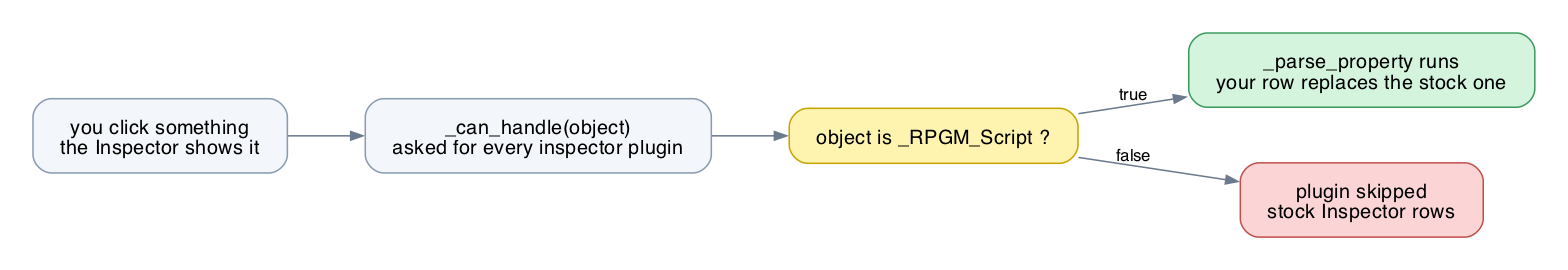

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  click [label="you click something\nthe Inspector shows it"];
  ask   [label="_can_handle(object)\nasked for every inspector plugin"];
  check [label="object is _RPGM_Script ?", fillcolor="#fff3b0", color="#c9a400"];
  yes   [label="_parse_property runs\nyour row replaces the stock one", fillcolor="#d4f4dd", color="#3c9a5f"];
  no    [label="plugin skipped\nstock Inspector rows", fillcolor="#fbd5d5", color="#c0504d"];
  click -> ask -> check;
  check -> yes [label="true"];
  check -> no  [label="false"];
}
```

</details>

| What you click | `object` is | `is _RPGM_Script` |
|---|---|---|
| One `_RPGM_Script` node in the Scene tree | that node | **true**, your lambda queue rows appear |
| Any other node | that node | false |
| A `.tres` / `.res` file, or a resource opened from a property (material, tileset, a lambda) | that `Resource` | false |
| A sub-resource expanded inline in the Inspector | that `Resource` (asked again for the nested one) | false |
| Several nodes at once | an internal editor stand-in for the multi-selection | false, so stock array rows show |
| A node in the Remote tree while the game runs | an internal editor mirror of the remote node | false |
| Import settings, sections of some editor dialogs | other internal editor objects | false |

**To customise a lambda's own properties**, a second plugin would use `return object is _RPGM_Lambda`; it would also apply inside the values popup, which is a real Inspector. Not verified: lambda scripts are not `@tool`, so the instance is a placeholder in the editor. The same `is` test already works for `_RPGM_Script`, which is in the same situation.
